---
title: Periodogram Smoothing
---

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import cvxpy as cp
import mosek
import mne

Many time series have periodograms that look quite noisy. As an example, consider the neuroscience time series that we looked at in the last lecture. 

### EEG Motor Movement Dataset

The following dataset was downloaded from https://physionet.org/content/eegmmidb/1.0.0/. The specific dataset details are here: https://physionet.org/content/eegmmidb/1.0.0/. The dataset consists of over 1500 one and two minute (64 channel) EEG recordings, obtained from 109 volunteers. We will pick data for just one subject (volunteer) and one of the EEG channels, and compare the data for eyes open vs eyes closed. A basic finding of cognitive neuroscience is that the power of occipital alpha-band (~10 Hz) brain waves is increased when peoples' eyes are closed, rather than open (see, for example, the paper titled "Occipital alpha-band brain waves when the eyes are closed are shaped by ongoing visual processes" by Hohaia et al 2022). 

For each individual subject (here we are using the data for the first subject), there are 64 time series datasets for "open-eyes" and again 64 time series datasets for "closed-eyes". These 64 datasets correspond to the 64 channels which are different electrodes recording brain activity. We pick one of the channels, and compare the "open-eyes" and "closed-eyes" data. 

Extracting EDF parameters from S001R01.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>


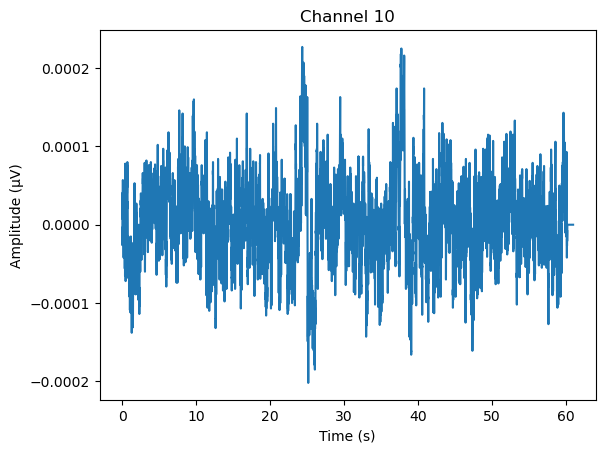

In [2]:
#This is the dataset for the eyes-open setting:
raw_1 = mne.io.read_raw_edf('S001R01.edf', preload = True)
print(raw_1.info)
data_1, times_1 = raw_1[:]

ch_index = 10  # pick a channel 
#plt.figure(figsize=(12,6))
plt.plot(times_1, data_1[ch_index, :])
plt.title(f"Channel {ch_index}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (µV)")
plt.show()

Extracting EDF parameters from S001R02.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 9759  =      0.000 ...    60.994 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: Fc5., Fc3., Fc1., Fcz., Fc2., Fc4., Fc6., C5.., C3.., C1.., ...
 chs: 64 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 80.0 Hz
 meas_date: 2009-08-12 16:15:00 UTC
 nchan: 64
 projs: []
 sfreq: 160.0 Hz
 subject_info: <subject_info | his_id: X, sex: 0, last_name: X>
>


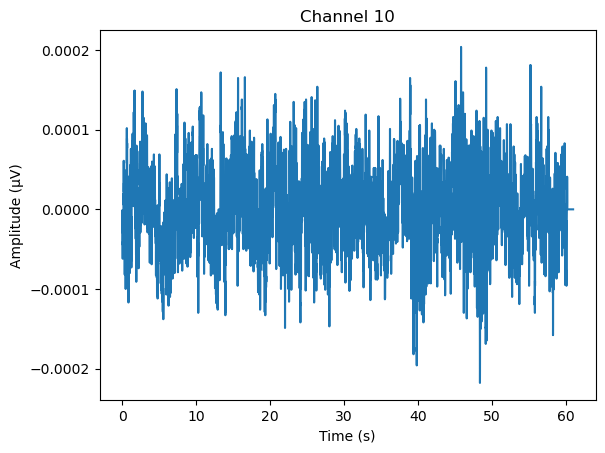

In [3]:
#Here is the dataset for the eyes closed setting. 
raw_2 = mne.io.read_raw_edf('S001R02.edf', preload = True)
print(raw_2.info)
data_2, times_2 = raw_2[:]

#plt.figure(figsize=(12,6))
plt.plot(times_2, data_2[ch_index, :])
plt.title(f"Channel {ch_index}")
plt.xlabel("Time (s)")
plt.ylabel("Amplitude (µV)")
plt.show()

There is a sampling rate associated with these datasets. This is the number of times per second that the data is obtained. 

In [4]:
sampling_rate_1 = raw_1.info['sfreq']
print("Sampling rate:", sampling_rate_1, "Hz")
sampling_rate_2 = raw_2.info['sfreq']
print("Sampling rate:", sampling_rate_2, "Hz")
sampling_rate = sampling_rate_1

Sampling rate: 160.0 Hz
Sampling rate: 160.0 Hz


The length of these time series is 9760 (see below). This corresponds to 160 observations per second, for a total of 61 seconds. 

In [5]:
print(times_1)
print(times_2)
n = len(times_1)
print(n, n/sampling_rate) 

[0.000000e+00 6.250000e-03 1.250000e-02 ... 6.098125e+01 6.098750e+01
 6.099375e+01]
[0.000000e+00 6.250000e-03 1.250000e-02 ... 6.098125e+01 6.098750e+01
 6.099375e+01]
9760 61.0


Our two datasets are:

In [6]:
y_o = data_1[ch_index, :]
y_c = data_2[ch_index, :]

Our main goal is to compare these two datasets and to highlight the main ways in which they are different. 

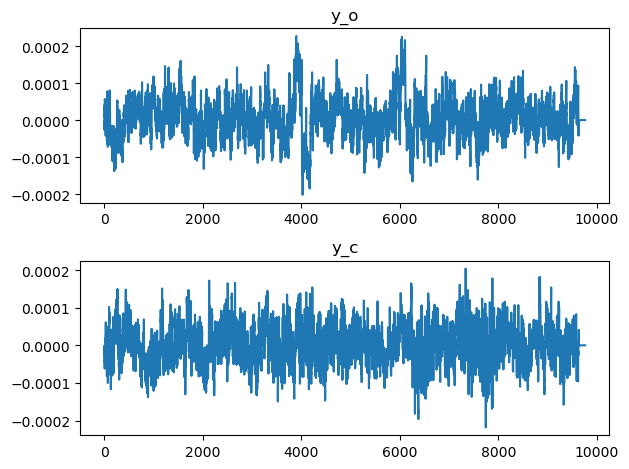

In [7]:
#fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 6))
fig, axes = plt.subplots(nrows = 2, ncols = 1)

axes[0].plot(y_o)
axes[0].set_title('y_o')

axes[1].plot(y_c)
axes[1].set_title('y_c')

plt.tight_layout()
plt.show()

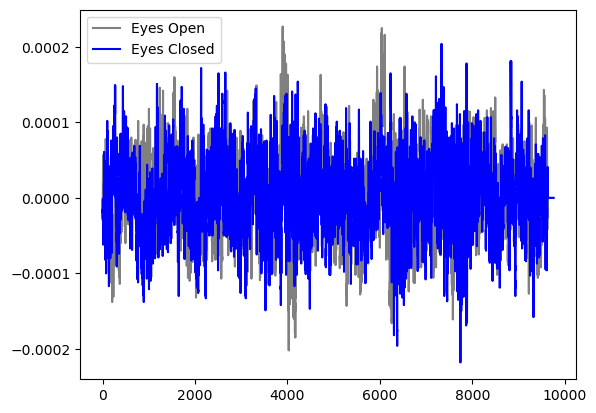

In [8]:
plt.plot(y_o, label = 'Eyes Open', color = 'gray')
plt.plot(y_c, label = 'Eyes Closed', color = 'blue')
plt.legend()
plt.show()

It is obviously very hard to articulate the differences between the two time series just by looking at their plots. For such datasets, the basic tool is the Periodogram. Recall that the periodogram is given by: 
\begin{align*}
   I(j/n) := \frac{|b_j|^2}{n}
\end{align*}
where $b_j$ is given by the Discrete Fourier Transform. We plot the periodogram when $j/n$ lies between 0 and $1/2$. 

In [9]:
def periodogram(y):
    fft_y = np.fft.fft(y)
    n = len(y)
    fourier_freqs = np.arange(1/n, 1/2, 1/n)
    m = len(fourier_freqs)
    pgram_y = (np.abs(fft_y[1:m+1]) ** 2)/n
    return fourier_freqs, pgram_y

In [10]:
n = len(y_o)
freqs, pgram_o = periodogram(y_o)
freqs, pgram_c = periodogram(y_c)


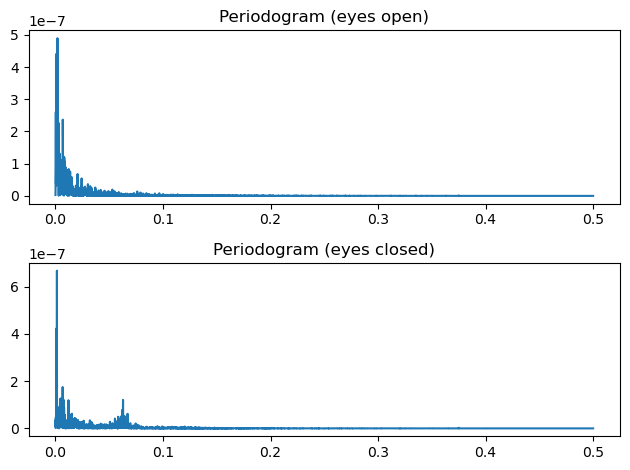

In [11]:
fig, axes = plt.subplots(nrows = 2, ncols = 1)

axes[0].plot(freqs, pgram_o)
axes[0].set_title('Periodogram (eyes open)')

axes[1].plot(freqs, pgram_c)
axes[1].set_title('Periodogram (eyes closed)')

plt.tight_layout()
plt.show()

The differences are more apparent from the periodograms. To see them better, we plot the periodograms on the log-scale. 

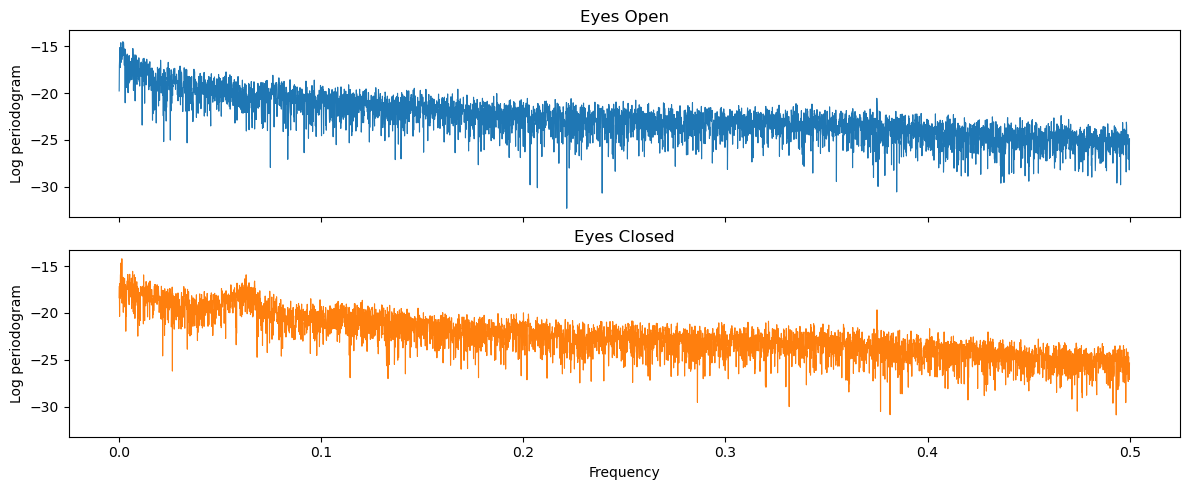

In [12]:
fig, axes = plt.subplots(
    2, 1, figsize=(12, 5), sharex=True, sharey=True
)

axes[0].plot(freqs, np.log(pgram_o), color='tab:blue', linewidth=0.8)
axes[0].set_title('Eyes Open')

axes[1].plot(freqs, np.log(pgram_c), color='tab:orange', linewidth=0.8)
axes[1].set_title('Eyes Closed')

for ax in axes:
    ax.set_ylabel('Log periodogram')

axes[1].set_xlabel('Frequency')

fig.tight_layout(h_pad=0.6)
plt.show()

Below we plot the log-periodograms in the same plot. 

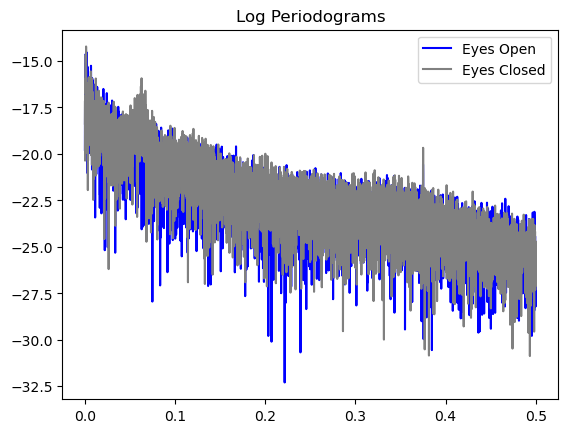

In [13]:
plt.plot(freqs, np.log(pgram_o), label = 'Eyes Open', color = 'blue')
plt.plot(freqs, np.log(pgram_c), label = 'Eyes Closed', color = 'gray')
plt.title('Log Periodograms')
plt.legend()
plt.show()

There certainly are differences between the two periodograms. These differences can be seen better if we smooth these periodograms. For this, we use the model: $\text{Re}(b_j), \text{Im}(b_j) \overset{\text{i.i.d}}{\sim} N(0, \gamma_j^2)$ for $j = 1, \dots, m$ (here $m = (n-1)/2$), where $b_0, \dots, b_{n-1}$ denote the DFT of the observed data $y_t$. The parameters underlying this model are $\gamma_1^2, \dots, \gamma_m^2$. The model can be written in terms of the periodogram $I(j/n)$ as
\begin{equation*}
   I(j/n) = \frac{|b_j|^2}{n} \overset{\text{ind}}{\sim} f(j/n) \eta_j
\end{equation*}
where $\eta_j \overset{\text{i.i.d}}{\sim} Exp(1)$. The mean of the periodogram $f(j/n)$ is called the power of frequency $j/n$. The relation between $f(j/n)$ and $\gamma_j$ is given by 
\begin{equation*}
   f(j/n) = \frac{2 \gamma_j^2}{n} ~~~ \text{ for } j = 1, \dots, m. 
\end{equation*}
If we treat $f(j/n)$ as a function on $[0, 1/2]$ (say by joining successive values by lines), we obtain the power spectral density function.

To estimate $\gamma_j, j = 1, \dots, m$ in the spectrum model, we use the following estimators (below $\alpha_j = \log \gamma_j$)
\begin{equation*}
   \sum_{j=1}^m \left( \frac{nI(j/n)}{2} e^{-2 \alpha_j} + 2 \alpha_j \right)  + \lambda \sum_{j=2}^{m-1} \left((\alpha_{j+1} - \alpha_j) - (\alpha_j - \alpha_{j-1}) \right)^2
\end{equation*}
or
\begin{equation*}
    \sum_{j=1}^m \left( \frac{nI(j/n)}{2} e^{-2 \alpha_j} + 2 \alpha_j \right) + \lambda \sum_{j=2}^{m-1} \left|(\alpha_{j+1} - \alpha_j) - (\alpha_j - \alpha_{j-1}) \right|.
\end{equation*}

The estimate of $\alpha_j$ can be converted to the power by 
\begin{equation*}
   f(j/n) = \mathbb{E} I(j/n) = \frac{2 \gamma_j^2}{n} = \frac{2}{n} e^{2 \alpha_j}
\end{equation*}

In [14]:
def spectrum_estimator_ridge(y, lambda_val):
    freq, I = periodogram(y)
    m = len(freq)
    n = len(y)
    alpha = cp.Variable(m)
    neg_likelihood_term = cp.sum(cp.multiply((n * I / 2), cp.exp(-2 * alpha)) + 2*alpha)
    smoothness_penalty = cp.sum(cp.square(alpha[2:] - 2 * alpha[1:-1] + alpha[:-2]))
    objective = cp.Minimize(neg_likelihood_term + lambda_val * smoothness_penalty)
    problem = cp.Problem(objective)
    problem.solve(solver = cp.MOSEK)
    return alpha.value, freq

def spectrum_estimator_lasso(y, lambda_val):
    freq, I = periodogram(y)
    m = len(freq)
    n = len(y) 
    alpha = cp.Variable(m)
    neg_likelihood_term = cp.sum(cp.multiply((n * I / 2), cp.exp(-2 * alpha)) + 2*alpha)
    smoothness_penalty = cp.sum(cp.abs(alpha[2:] - 2 * alpha[1:-1] + alpha[:-2]))
    objective = cp.Minimize(neg_likelihood_term + lambda_val * smoothness_penalty)
    problem = cp.Problem(objective)
    problem.solve(solver = cp.MOSEK)
    return alpha.value, freq

In [15]:
#Eyes open
n_o = len(y_o)
freqs_o, pgram_o = periodogram(y_o)
alpha_opt_ridge_o, freq = spectrum_estimator_ridge(y_o, 50000000)
pgram_mean_ridge_o = (2/n_o)*(np.exp(2*alpha_opt_ridge_o))
alpha_opt_lasso_o, freq = spectrum_estimator_lasso(y_o, 1000)
pgram_mean_lasso_o = (2/n_o)*(np.exp(2*alpha_opt_lasso_o))

#Eyes closed
n_c = len(y_c)
freqs_c, pgram_c = periodogram(y_c)
alpha_opt_ridge_c, freq = spectrum_estimator_ridge(y_c, 50000000)
pgram_mean_ridge_c = (2/n_c)*(np.exp(2*alpha_opt_ridge_c))
alpha_opt_lasso_c, freq = spectrum_estimator_lasso(y_c, 1000)
pgram_mean_lasso_c = (2/n_c)*(np.exp(2*alpha_opt_lasso_c))

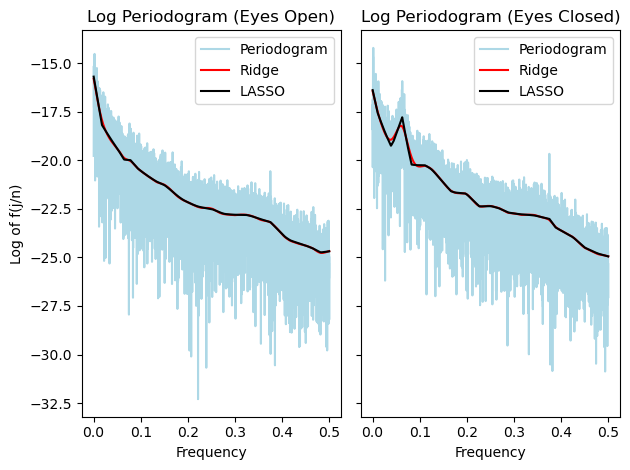

In [16]:
fig, axes = plt.subplots(1, 2, sharey=True)

# ----- Left subplot: Eyes Open -----
axes[0].plot(freqs, np.log(pgram_o), color='lightblue', label='Periodogram')
axes[0].plot(freqs, np.log(pgram_mean_ridge_o), color='red', label='Ridge')
axes[0].plot(freqs, np.log(pgram_mean_lasso_o), color='black', label='LASSO')
axes[0].set_title('Log Periodogram (Eyes Open)')
axes[0].set_xlabel('Frequency')
axes[0].set_ylabel('Log of f(j/n)')
axes[0].legend()

# ----- Right subplot: Eyes Closed -----
axes[1].plot(freqs, np.log(pgram_c), color='lightblue', label='Periodogram')
axes[1].plot(freqs, np.log(pgram_mean_ridge_c), color='red', label='Ridge')
axes[1].plot(freqs, np.log(pgram_mean_lasso_c), color='black', label='LASSO')
axes[1].set_title('Log Periodogram (Eyes Closed)')
axes[1].set_xlabel('Frequency')
axes[1].legend()

plt.tight_layout()
plt.show()

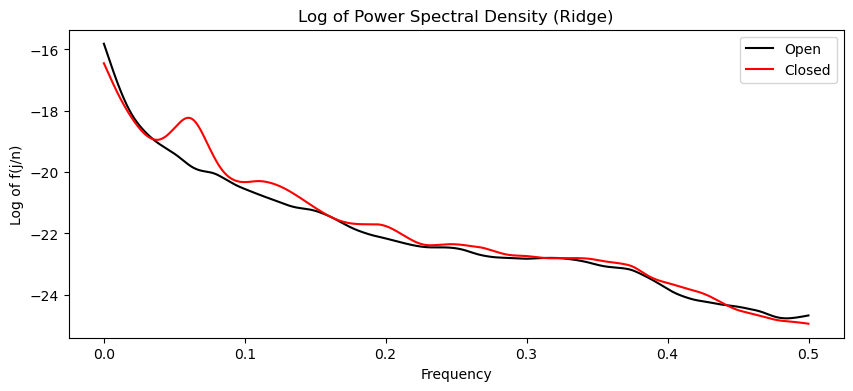

In [17]:
plt.figure(figsize = (10, 4))
plt.plot(freqs, np.log(pgram_mean_ridge_o), color = 'black', label = 'Open')
plt.plot(freqs, np.log(pgram_mean_ridge_c), color = 'red', label = 'Closed')
plt.title('Log of Power Spectral Density (Ridge)')
plt.xlabel('Frequency')
plt.ylabel('Log of f(j/n)')
plt.legend()
plt.show()

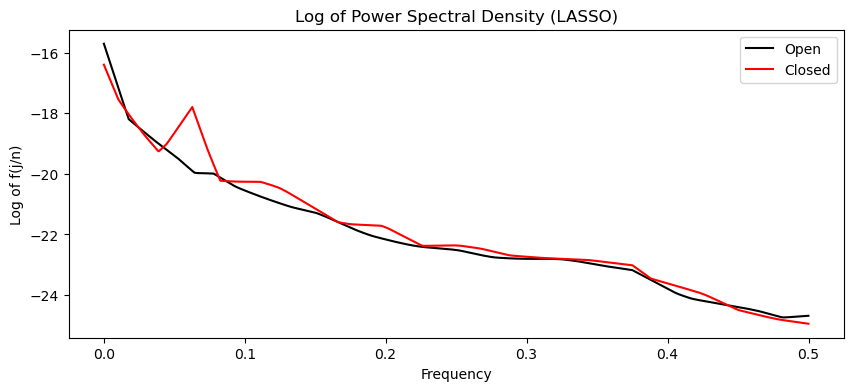

In [18]:
plt.figure(figsize = (10, 4))
plt.plot(freqs, np.log(pgram_mean_lasso_o), color = 'black', label = 'Open')
plt.plot(freqs, np.log(pgram_mean_lasso_c), color = 'red', label = 'Closed')
plt.title('Log of Power Spectral Density (LASSO)')
plt.xlabel('Frequency')
plt.ylabel('Log of f(j/n)')
plt.legend()
plt.show()

The peak in the 'eyes closed' curve above can be computed as follows. 

[0.06270492 0.1079918  0.24518443]


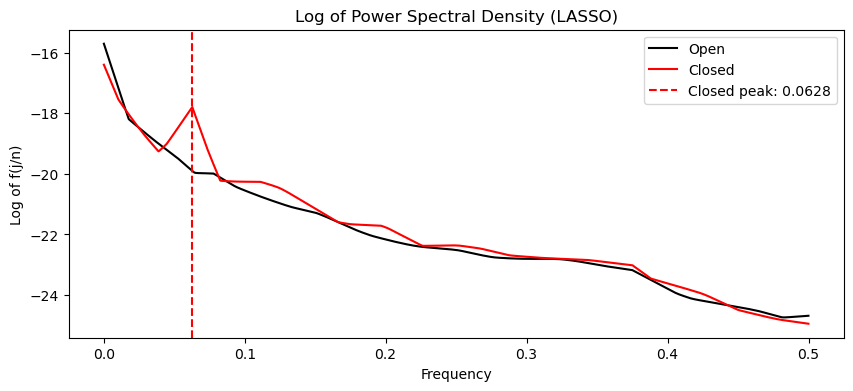

In [19]:
from scipy.signal import find_peaks
# Find peaks
peaks, _ = find_peaks(np.log(pgram_mean_lasso_c))
print(peaks/n)

peak = peaks[0]
plt.figure(figsize = (10, 4))
plt.plot(freqs, np.log(pgram_mean_lasso_o), color = 'black', label = 'Open')
plt.plot(freqs, np.log(pgram_mean_lasso_c), color = 'red', label = 'Closed')
plt.axvline(freqs[peak], color = 'red', linestyle = '--',
            label = f'Closed peak: {freqs[peak]:.4f}')
plt.title('Log of Power Spectral Density (LASSO)')
plt.xlabel('Frequency')
plt.ylabel('Log of f(j/n)')
plt.legend()
plt.show()

The peak corresponds to the frequency $0.06270492$. To convert the frequency to Hertz, we multiply it by the sampling rate. 

In [20]:
(peaks[0]/n) * sampling_rate

10.032786885245901

So the differences between the two smoothed periodogram estimates is mainly at frequency 10.0328 Hz. This is very close to the 10Hz Alpha rhythm which apparently exists when eyes are closed as opposed to eyes being open (see, for example, the first sentence in this paper "Occipital alpha-band brain waves when the eyes are closed are shaped by ongoing visual processes" by Hohaia et al 2022). The wiki page on the alpha wave (see https://en.wikipedia.org/wiki/Alpha_wave) says that alpha waves are neural oscillations in the frequency range 8-12 Hz. We can see from the plot above that at 8 - 12 Hz, the estimated spectrum for the closed eyes data is higher than the spectrm for open eyes data. 

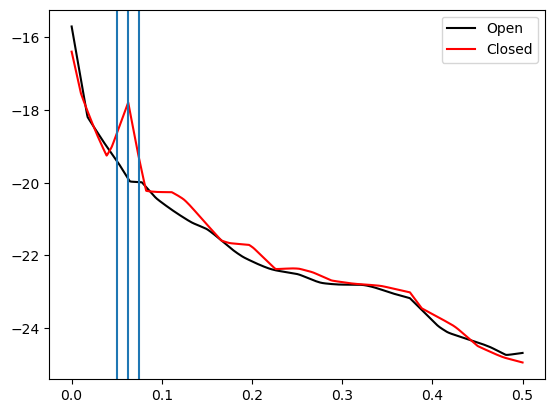

In [21]:
#Estimated power spectra
plt.plot(freqs, np.log(pgram_mean_lasso_o), color = 'black', label = 'Open')
plt.plot(freqs, np.log(pgram_mean_lasso_c), color = 'red', label = 'Closed')
plt.axvline(x = 10/sampling_rate)
plt.axvline(x = 8/sampling_rate)
plt.axvline(x = 12/sampling_rate)
plt.legend()
plt.show()

### Application: Quake Vibration Dataset

This dataset is from the Mathworks (MATLAB) tutorial "Practical Introduction to Frequency-Domain Analysis" (see [this link](https://www.mathworks.com/help/signal/ug/practical-introduction-to-frequency-domain-analysis.html)). From this matlab tutorial: *Active Mass Driver (AMD) control systems are used to reduce vibration in a building under an earthquake. An active mass driver is placed on the top floor of the building and, based on displacement and acceleration measurements of the building floors, a control system sends signals to the driver so that the mass moves to attenuate ground disturbances. Acceleration measurements were recorded on the first floor of a three story test structure under earthquake conditions. Measurements were taken without the active mass driver control system (open loop condition), and with the active control system (closed loop condition).*

In [22]:
from scipy.io import loadmat
mat_dict = loadmat('quakevibration.mat')
print(mat_dict.keys())

dict_keys(['__header__', '__version__', '__globals__', 'gfloor1OL', 'gfloor1CL'])


In [23]:
gfloor1OL_array = mat_dict['gfloor1OL']
gfloor1CL_array = mat_dict['gfloor1CL']
print(gfloor1OL_array.shape)
print(gfloor1CL_array.shape)

(10000, 1)
(10000, 1)


In [24]:
y_ol = gfloor1OL_array.ravel()
y_cl = gfloor1CL_array.ravel()

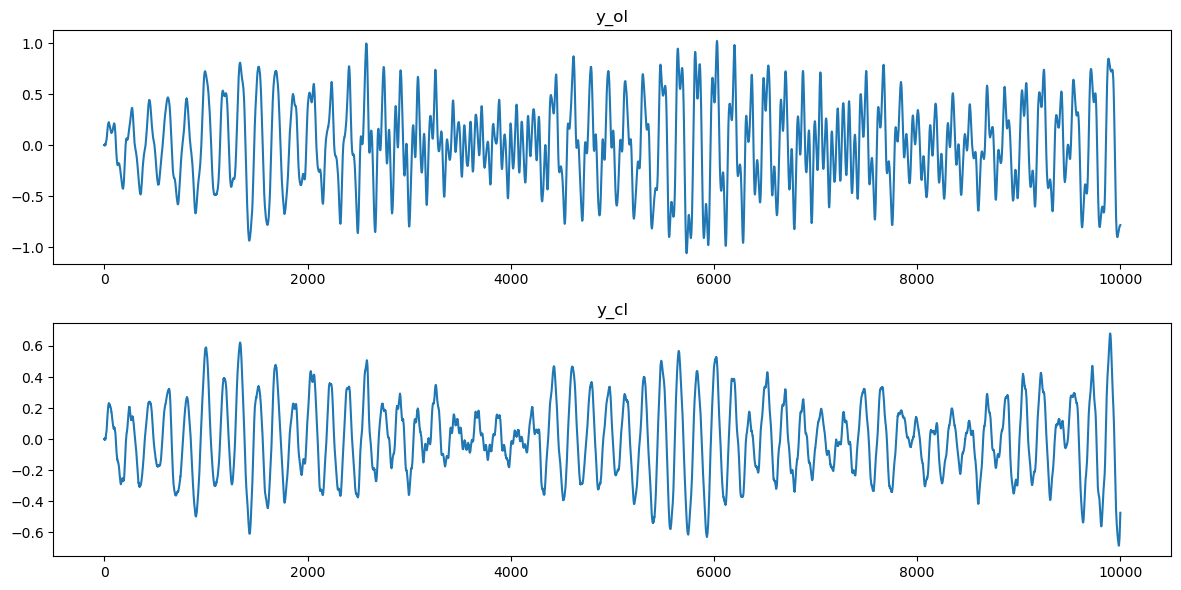

In [25]:
fig, axes = plt.subplots(nrows = 2, ncols = 1, figsize = (12, 6))

axes[0].plot(y_ol)
axes[0].set_title('y_ol')

axes[1].plot(y_cl)
axes[1].set_title('y_cl')

plt.tight_layout()
plt.show()

In [26]:
n = len(y_ol)
freqs, pgram_ol = periodogram(y_ol)
alpha_opt_ridge_ol, freq = spectrum_estimator_ridge(y_ol, 100000)
pgram_mean_ridge_ol = (2/n)*(np.exp(2*alpha_opt_ridge_ol))
alpha_opt_lasso_ol, freq = spectrum_estimator_lasso(y_ol, 1000)
pgram_mean_lasso_ol = (2/n)*(np.exp(2*alpha_opt_lasso_ol))

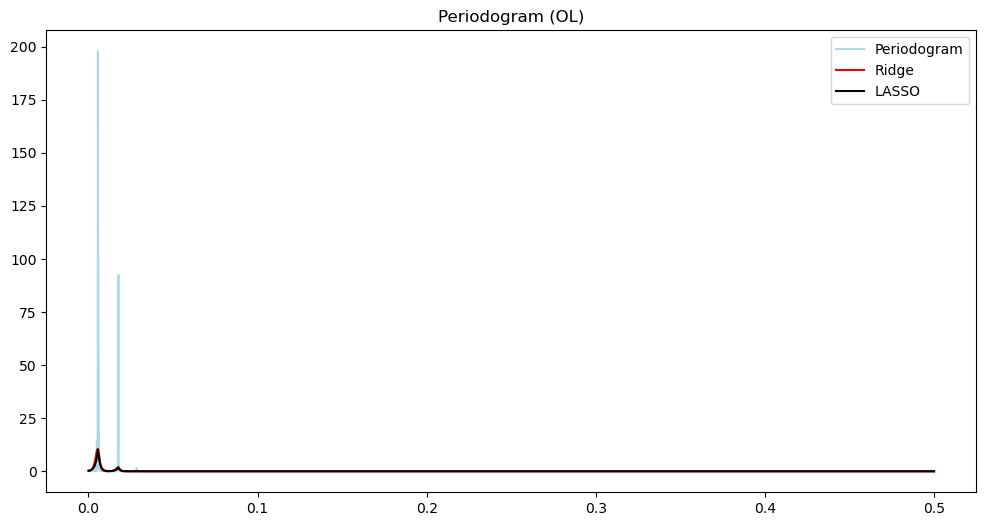

In [27]:
plt.figure(figsize = (12, 6))
plt.plot(freqs, (pgram_ol), color = 'lightblue', label = 'Periodogram')
#plt.plot(freqs, np.log(pgram_ol), color = 'None', label = 'Periodogram')
plt.title('Periodogram (OL)')
plt.plot(freqs, (pgram_mean_ridge_ol), color = 'red', label = 'Ridge')
plt.plot(freqs, (pgram_mean_lasso_ol), color = 'black', label = 'LASSO')
plt.legend()
plt.show()

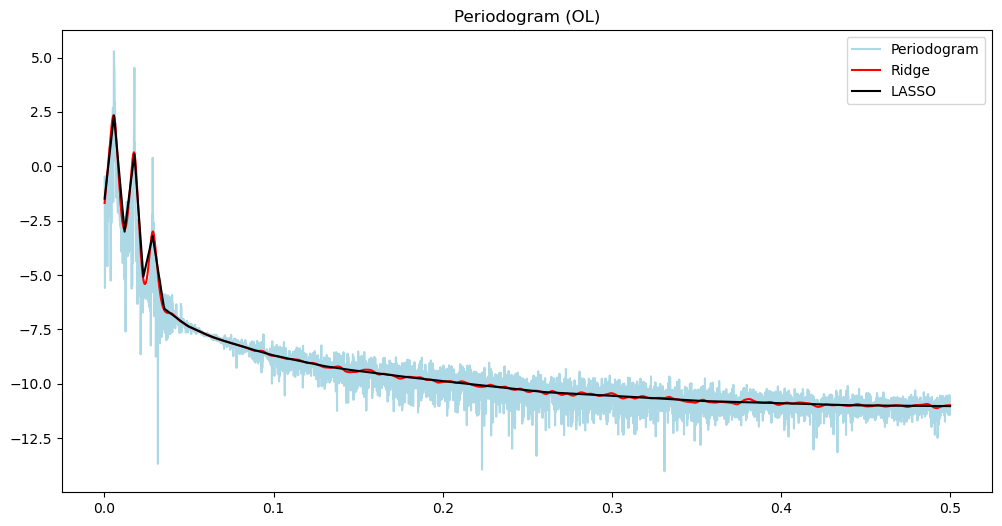

In [28]:
plt.figure(figsize = (12, 6))
plt.plot(freqs, np.log(pgram_ol), color = 'lightblue', label = 'Periodogram')
#plt.plot(freqs, np.log(pgram_ol), color = 'None', label = 'Periodogram')
plt.title('Periodogram (OL)')
plt.plot(freqs, np.log(pgram_mean_ridge_ol), color = 'red', label = 'Ridge')
plt.plot(freqs, np.log(pgram_mean_lasso_ol), color = 'black', label = 'LASSO')
plt.legend()
plt.show()

In [29]:
n = len(y_cl)
freqs, pgram_cl = periodogram(y_cl)
alpha_opt_ridge_cl, freq = spectrum_estimator_ridge(y_cl, 100000)
pgram_mean_ridge_cl = (2/n)*(np.exp(2*alpha_opt_ridge_cl))
alpha_opt_lasso_cl, freq = spectrum_estimator_lasso(y_cl, 1000)
pgram_mean_lasso_cl = (2/n)*(np.exp(2*alpha_opt_lasso_cl))

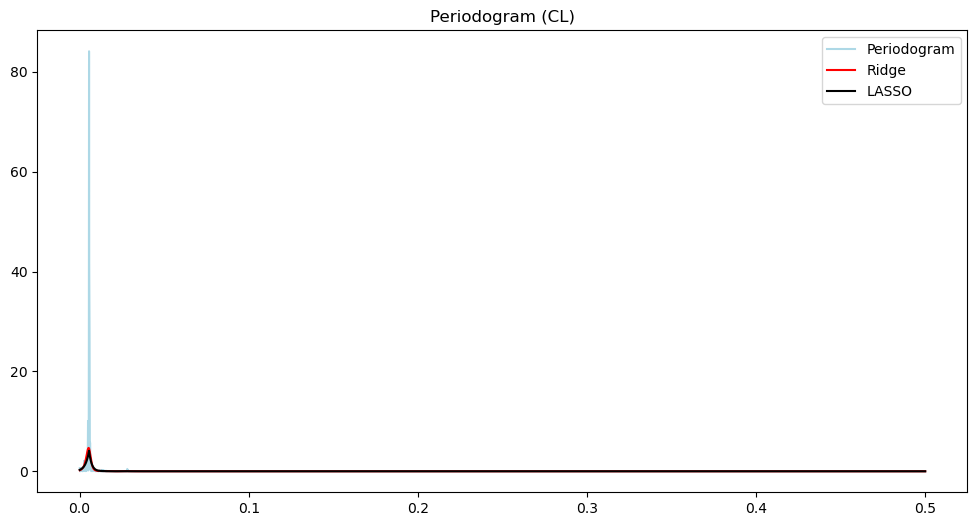

In [30]:
plt.figure(figsize = (12, 6))
plt.plot(freqs, (pgram_cl), color = 'lightblue', label = 'Periodogram')
#plt.plot(freqs, np.log(pgram_cl), color = 'None', label = 'Periodogram')
plt.title('Periodogram (CL)')
plt.plot(freqs, (pgram_mean_ridge_cl), color = 'red', label = 'Ridge')
plt.plot(freqs, (pgram_mean_lasso_cl), color = 'black', label = 'LASSO')
plt.legend()
plt.show()

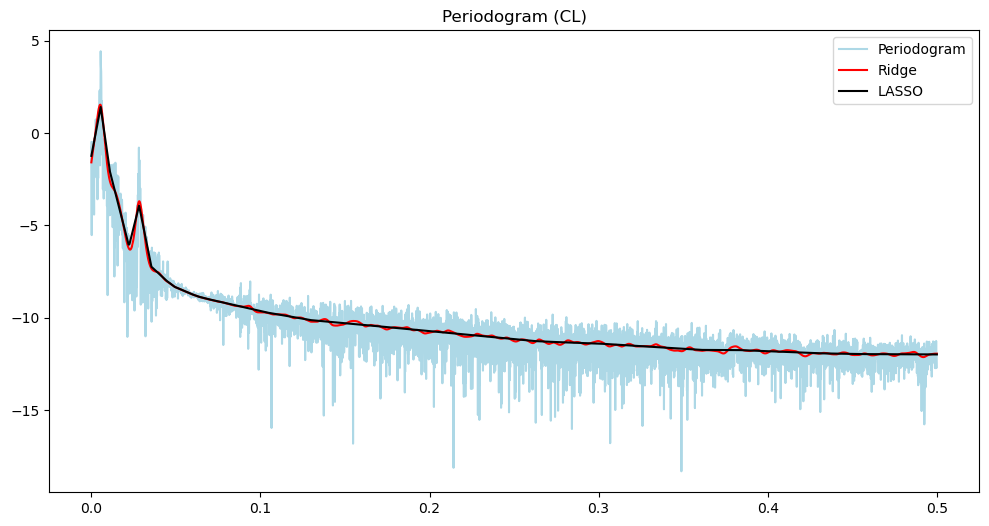

In [31]:
plt.figure(figsize = (12, 6))
plt.plot(freqs, np.log(pgram_cl), color = 'lightblue', label = 'Periodogram')
#plt.plot(freqs, np.log(pgram_cl), color = 'None', label = 'Periodogram')
plt.title('Periodogram (CL)')
plt.plot(freqs, np.log(pgram_mean_ridge_cl), color = 'red', label = 'Ridge')
plt.plot(freqs, np.log(pgram_mean_lasso_cl), color = 'black', label = 'LASSO')
plt.legend()
plt.show()

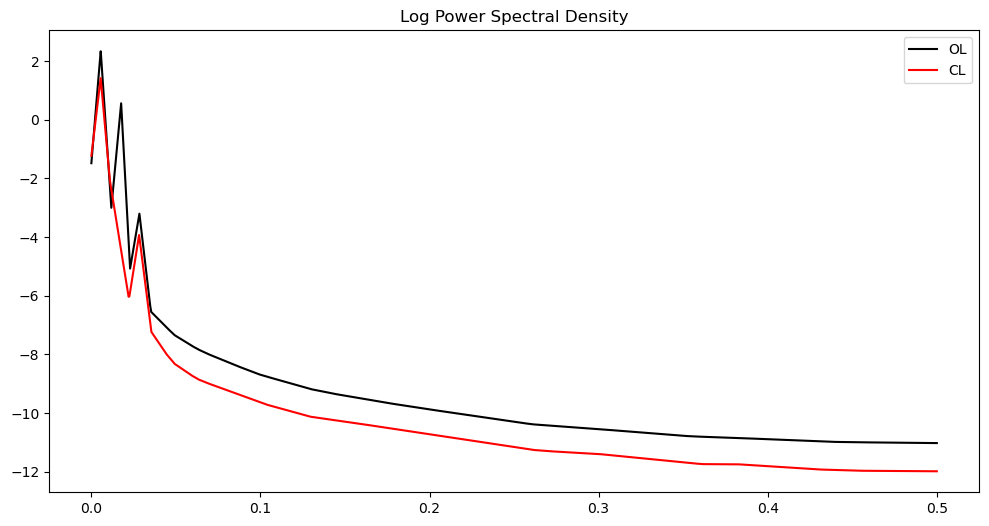

In [32]:
plt.figure(figsize = (12, 6))
plt.plot(freqs, np.log(pgram_mean_lasso_ol), color = 'black', label = 'OL')
plt.plot(freqs, np.log(pgram_mean_lasso_cl), color = 'red', label = 'CL')
plt.legend()
plt.title('Log Power Spectral Density')
plt.show()

There are three loops on the open loop spectrum and two on the closed loop spectrum. The control system reduces the overall power of the vibrations and gets rid of one harmonic component. In other words, the control system not only reduces the vibration but also brings it closer to a sinusoid. 

The main point is that the differences between the two time series is much better summarized using their power spectra, compared to the raw data. 